# Monod CME Model Demo

This notebook demonstrates the six two-modality (unspliced + spliced) CME models
available in the Monod package.  For each model we:

1. Explain the biological interpretation of the parameters.
2. Compute the steady-state probability mass function (PSS) on a grid.
3. Visualise the joint distribution and its marginals.

At the end we show a parameter-sensitivity sweep, a side-by-side model comparison,
and a fit of one model to real data through the `inference` module.

All heavy lifting is handled automatically by the Rust / GPU backend — no extra
configuration needed.

In [1]:
# Work from the repository root (data in example_h5ad/, figures in figures/)
# and import monod from src/ when running against a checkout.
import os, sys
_root = os.getcwd()
while not os.path.exists(os.path.join(_root, 'setup.cfg')) and os.path.dirname(_root) != _root:
    _root = os.path.dirname(_root)
os.chdir(_root)
if os.path.isdir(os.path.join(_root, 'src')) and os.path.join(_root, 'src') not in sys.path:
    sys.path.insert(0, os.path.join(_root, 'src'))


In [2]:
import sys, os

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from monod.cme_toolbox import CMEModel

# Check which backends are active
from monod.cme_toolbox import _HAS_RUST, _HAS_GPU
os.makedirs('figures', exist_ok=True)
print(f'Rust backend : {_HAS_RUST}')
print(f'GPU  backend : {_HAS_GPU}')

Rust backend : True
GPU  backend : False


In [3]:
# ── Shared plotting helpers ──────────────────────────────────────────────────

def plot_joint_and_marginals(pss, title, param_str, cmap='Blues', save_path=None):
    """Plot joint PMF (heatmap) with marginals on the side axes."""
    fig = plt.figure(figsize=(6, 5))
    gs  = fig.add_gridspec(2, 2, width_ratios=[4, 1], height_ratios=[1, 4],
                           hspace=0.05, wspace=0.05)
    ax_joint  = fig.add_subplot(gs[1, 0])
    ax_top    = fig.add_subplot(gs[0, 0], sharex=ax_joint)
    ax_right  = fig.add_subplot(gs[1, 1], sharey=ax_joint)

    # joint
    im = ax_joint.imshow(pss.T, origin='lower', aspect='auto',
                         cmap=cmap, norm=mcolors.PowerNorm(gamma=0.4, vmin=0))
    ax_joint.set_xlabel('Unspliced count', fontsize=11)
    ax_joint.set_ylabel('Spliced count',   fontsize=11)

    # marginals
    marg_u = pss.sum(axis=1)
    marg_s = pss.sum(axis=0)
    ax_top.plot(marg_u, color='steelblue', lw=1.5)
    ax_top.fill_between(range(len(marg_u)), marg_u, alpha=0.3, color='steelblue')
    ax_top.set_ylabel('P(u)', fontsize=9)
    ax_right.plot(marg_s, range(len(marg_s)), color='salmon', lw=1.5)
    ax_right.fill_betweenx(range(len(marg_s)), marg_s, alpha=0.3, color='salmon')
    ax_right.set_xlabel('P(s)', fontsize=9)

    # decorations
    plt.setp(ax_top.get_xticklabels(),   visible=False)
    plt.setp(ax_right.get_yticklabels(), visible=False)
    fig.suptitle(f'{title}\n{param_str}', fontsize=11, y=1.01)
    plt.colorbar(im, ax=[ax_joint, ax_right], label='Probability', shrink=0.8)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


def eval_pss(model_name, p_log, limits=(60, 80)):
    """Convenience: create model, evaluate, return PSS array."""
    model = CMEModel(model_name, 'None')
    return model.eval_model_pss(np.array(p_log), list(limits))

---
## 1 · Constitutive model

Transcription occurs at a **constant rate** $\alpha$.  The log-PGF is

$$\phi(g) = \frac{\alpha}{\beta}\,g_u + \frac{\alpha}{\gamma}\,g_s$$

giving **independent Poisson** marginals for unspliced ($u$) and spliced ($s$) counts.

| Parameter | Symbol | Meaning |
|-----------|--------|---------|
| `p[0]`    | $\log_{10}\beta$ | unspliced degradation rate |
| `p[1]`    | $\log_{10}\gamma$ | spliced degradation / splicing rate |

Mean unspliced = $\alpha/\beta$, mean spliced = $\alpha/\gamma$.

/tmp/ipykernel_2874520/4277292963.py:33: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


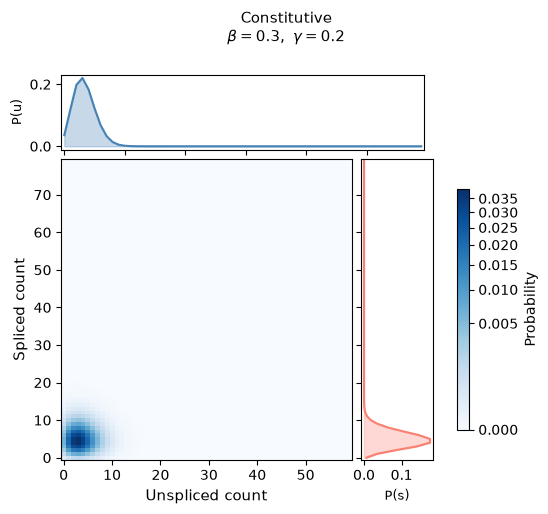

In [4]:
# beta=0.3, gamma=0.2  →  Poisson means ≈ 10 and 15
p_constitutive = [np.log10(0.3), np.log10(0.2)]
pss = eval_pss('Constitutive', p_constitutive)
plot_joint_and_marginals(
    pss, 'Constitutive',
    r'$\beta=0.3,\ \gamma=0.2$'
)

---
## 2 · Bursty model

Transcription occurs in **bursts** of geometrically-distributed size $b$.
The log-PGF integrates the burst-generating function along the ODE characteristics:

$$\phi(g) = \int_0^T \frac{b\,U(\tau,g)}{1 - b\,U(\tau,g)}\,d\tau$$

The marginals are **negative-binomial-like**, with heavier tails than the Constitutive
model at the same mean.

| Parameter | Symbol | Meaning |
|-----------|--------|---------|
| `p[0]`    | $\log_{10}b$ | mean burst size |
| `p[1]`    | $\log_{10}\beta$ | unspliced degradation rate |
| `p[2]`    | $\log_{10}\gamma$ | spliced degradation / splicing rate |

/tmp/ipykernel_2874520/4277292963.py:33: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


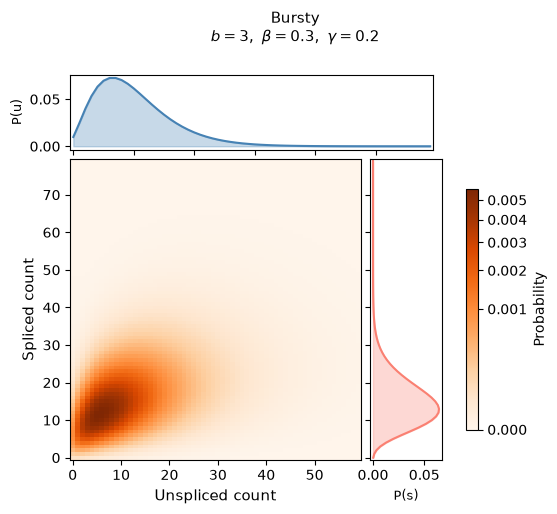

In [5]:
# b=3, beta=0.3, gamma=0.2
p_bursty = [np.log10(3), np.log10(0.3), np.log10(0.2)]
pss = eval_pss('Bursty', p_bursty)
plot_joint_and_marginals(
    pss, 'Bursty',
    r'$b=3,\ \beta=0.3,\ \gamma=0.2$',
    cmap='Oranges'
)

---
## 3 · CIR model

The Cox–Ingersoll–Ross (CIR) model is driven by an **inverse-Gaussian process**.
The integrand replaces $U/(1-U)$ with $(1-\sqrt{1-4U})/2$, yielding
**heavier tails** than the Bursty model.

| Parameter | Symbol | Meaning |
|-----------|--------|---------|
| `p[0]`    | $\log_{10}b$ | burst size analogue |
| `p[1]`    | $\log_{10}\beta$ | unspliced degradation rate |
| `p[2]`    | $\log_{10}\gamma$ | spliced degradation / splicing rate |

/tmp/ipykernel_2874520/4277292963.py:33: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


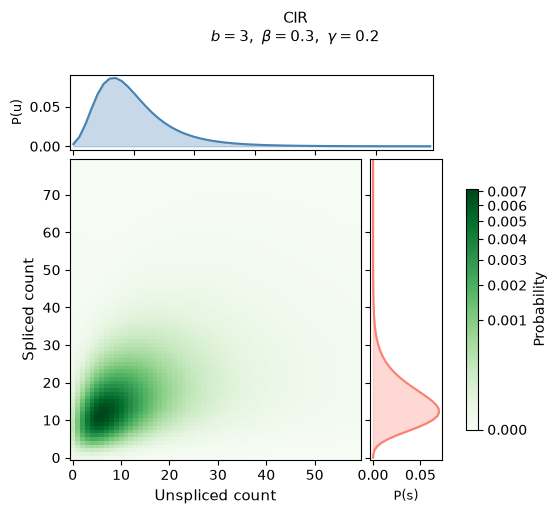

In [6]:
# Same parameters as Bursty for direct comparison
p_cir = [np.log10(3), np.log10(0.3), np.log10(0.2)]
pss = eval_pss('CIR', p_cir)
plot_joint_and_marginals(
    pss, 'CIR',
    r'$b=3,\ \beta=0.3,\ \gamma=0.2$',
    cmap='Greens'
)

---
## 4 · Extrinsic noise model

The transcription rate $k$ is **Gamma-distributed** (extrinsic noise), giving
a **negative-binomial** unspliced marginal and a correlated spliced distribution.

$$\phi(g) = -\alpha\,\ln\!\left(1 - \frac{g_u}{\beta} - \frac{g_s}{\gamma}\right)$$

| Parameter | Symbol | Meaning |
|-----------|--------|---------|
| `p[0]`    | $\log_{10}\alpha$ | shape of the Gamma rate distribution |
| `p[1]`    | $\log_{10}\beta$  | unspliced degradation rate |
| `p[2]`    | $\log_{10}\gamma$ | spliced degradation / splicing rate |

/tmp/ipykernel_2874520/4277292963.py:33: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


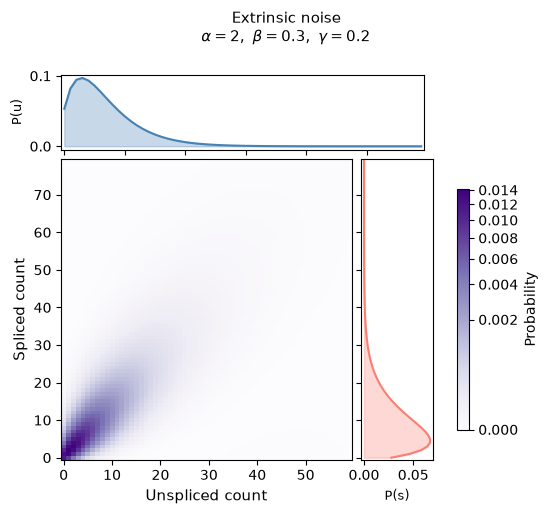

In [7]:
# alpha=2, beta=0.3, gamma=0.2
p_extrinsic = [np.log10(2), np.log10(0.3), np.log10(0.2)]
pss = eval_pss('Extrinsic', p_extrinsic)
plot_joint_and_marginals(
    pss, 'Extrinsic noise',
    r'$\alpha=2,\ \beta=0.3,\ \gamma=0.2$',
    cmap='Purples'
)

---
## 5 · Delay model

Bursty production with a **degradation delay** $\tau$ for unspliced RNA — a simple
model of co-transcriptional processing.

| Parameter | Symbol | Meaning |
|-----------|--------|---------|
| `p[0]`    | $\log_{10}b$         | mean burst size |
| `p[1]`    | $\log_{10}\beta$     | unspliced degradation rate |
| `p[2]`    | $\log_{10}\tau^{-1}$ | inverse delay (= splicing rate) |

/tmp/ipykernel_2874520/4277292963.py:33: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


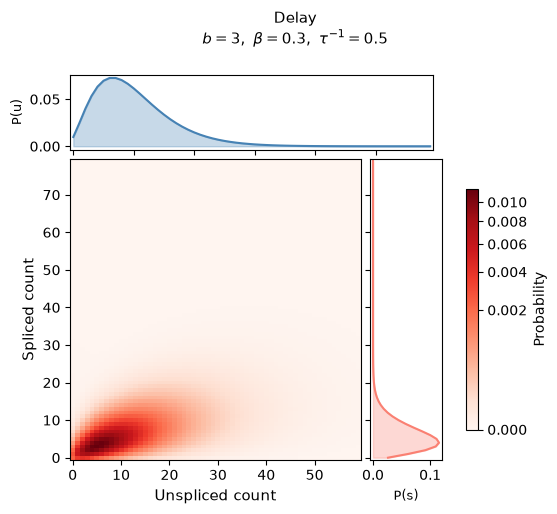

In [8]:
# b=3, beta=0.3, tauinv=0.5  (delay tau=2)
p_delay = [np.log10(3), np.log10(0.3), np.log10(0.5)]
pss = eval_pss('Delay', p_delay)
plot_joint_and_marginals(
    pss, 'Delay',
    r'$b=3,\ \beta=0.3,\ \tau^{-1}=0.5$',
    cmap='Reds'
)

---
## 6 · Delayed Splicing model

Bursty production where **splicing itself is delayed** by $\tau$, so unspliced RNA
accumulates before being converted to spliced.

| Parameter | Symbol | Meaning |
|-----------|--------|---------|
| `p[0]`    | $\log_{10}b$         | mean burst size |
| `p[1]`    | $\log_{10}\tau^{-1}$ | inverse splicing delay |
| `p[2]`    | $\log_{10}\gamma$    | spliced degradation rate |

/tmp/ipykernel_2874520/4277292963.py:33: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


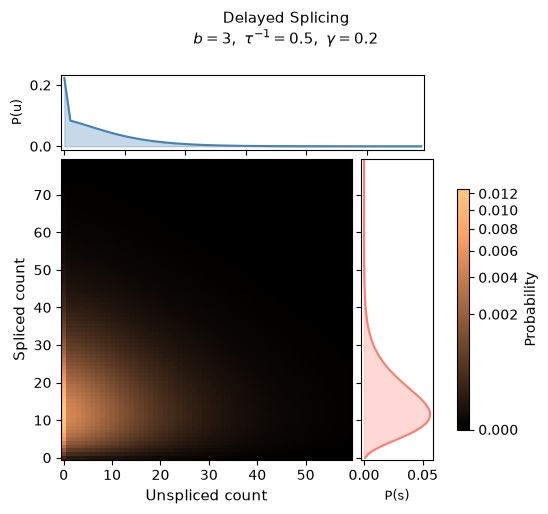

In [9]:
# b=3, tauinv=0.5, gamma=0.2
p_ds = [np.log10(3), np.log10(0.5), np.log10(0.2)]
pss = eval_pss('DelayedSplicing', p_ds)
plot_joint_and_marginals(
    pss, 'Delayed Splicing',
    r'$b=3,\ \tau^{-1}=0.5,\ \gamma=0.2$',
    cmap='copper'
)

---
## 7 · Parameter sensitivity — Bursty burst size

Increasing the mean burst size $b$ (with fixed $\beta$ and $\gamma$) increases
variance while keeping the mean approximately constant, broadening the marginals.

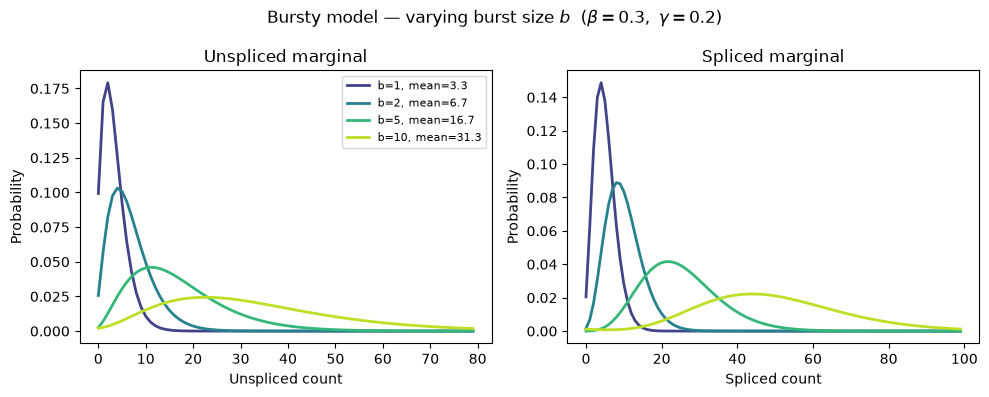

In [10]:
burst_sizes = [1, 2, 5, 10]
beta, gamma = 0.3, 0.2
model = CMEModel('Bursty', 'None')

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
colors = plt.cm.viridis(np.linspace(0.2, 0.9, len(burst_sizes)))

for b, col in zip(burst_sizes, colors):
    p = np.array([np.log10(b), np.log10(beta), np.log10(gamma)])
    pss = model.eval_model_pss(p, [80, 100])
    marg_u = pss.sum(axis=1)
    marg_s = pss.sum(axis=0)
    mean_u = (np.arange(len(marg_u)) * marg_u).sum()
    axes[0].plot(marg_u, color=col, lw=2, label=f'b={b}, mean={mean_u:.1f}')
    axes[1].plot(marg_s, color=col, lw=2, label=f'b={b}')

axes[0].set_xlabel('Unspliced count'); axes[0].set_ylabel('Probability')
axes[0].set_title('Unspliced marginal'); axes[0].legend(fontsize=8)
axes[1].set_xlabel('Spliced count');   axes[1].set_ylabel('Probability')
axes[1].set_title('Spliced marginal')
fig.suptitle(r'Bursty model — varying burst size $b$  ($\beta=0.3,\ \gamma=0.2$)', fontsize=12)
plt.tight_layout()
plt.savefig('figures/models_burst_sensitivity.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 8 · Model comparison at matched moments

All five three-parameter models are evaluated at the same values of $b$, $\beta$,
and $\gamma$ (or the analogue parameters), so differences reflect the noise
architecture rather than just parameter magnitudes.

We compare the **unspliced marginal** for Bursty, CIR, Extrinsic, Delay, and
Delayed Splicing.

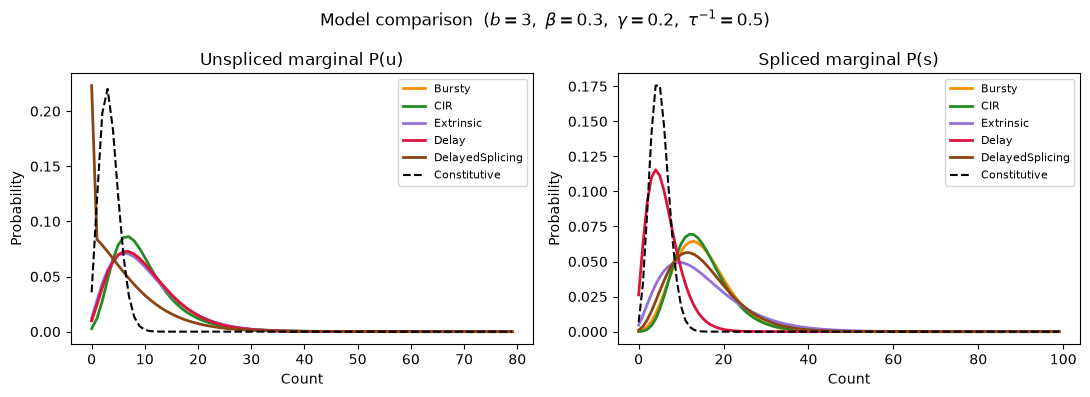

In [11]:
b, beta, gamma, tauinv = 3.0, 0.3, 0.2, 0.5
configs = {
    'Bursty':          [np.log10(b),    np.log10(beta), np.log10(gamma)],
    'CIR':             [np.log10(b),    np.log10(beta), np.log10(gamma)],
    'Extrinsic':       [np.log10(b),    np.log10(beta), np.log10(gamma)],
    'Delay':           [np.log10(b),    np.log10(beta), np.log10(tauinv)],
    'DelayedSplicing': [np.log10(b),    np.log10(tauinv), np.log10(gamma)],
}
colors_map = {
    'Bursty': 'darkorange', 'CIR': 'forestgreen',
    'Extrinsic': 'mediumpurple', 'Delay': 'crimson',
    'DelayedSplicing': 'saddlebrown',
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for name, p_log in configs.items():
    pss   = eval_pss(name, p_log, limits=(80, 100))
    marg_u = pss.sum(axis=1)
    marg_s = pss.sum(axis=0)
    col = colors_map[name]
    axes[0].plot(marg_u, color=col, lw=2, label=name)
    axes[1].plot(marg_s, color=col, lw=2, label=name)

# Also add Constitutive for reference (matched mean)
alpha_eff = b * beta   # alpha/beta = b  →  alpha = b*beta
p_const = [np.log10(alpha_eff / beta), np.log10(gamma)]  # note: Constitutive p=(beta,gamma)
# For Constitutive the synthesis rate is implicit; use beta=alpha_eff, gamma=gamma
model_c = CMEModel('Constitutive', 'None')
pss_c   = model_c.eval_model_pss(np.array([np.log10(beta), np.log10(gamma)]), [80, 100])
axes[0].plot(pss_c.sum(axis=1), 'k--', lw=1.5, label='Constitutive')
axes[1].plot(pss_c.sum(axis=0), 'k--', lw=1.5, label='Constitutive')

for ax, title in zip(axes, ['Unspliced marginal P(u)', 'Spliced marginal P(s)']):
    ax.set_xlabel('Count'); ax.set_ylabel('Probability')
    ax.set_title(title); ax.legend(fontsize=8)

fig.suptitle(
    r'Model comparison  ($b=3,\ \beta=0.3,\ \gamma=0.2,\ \tau^{-1}=0.5$)',
    fontsize=12
)
plt.tight_layout()
plt.savefig('figures/models_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 9 · Timing comparison

Quick benchmark to confirm the Rust / GPU backend is active.

In [12]:
import time

model_b = CMEModel('Bursty', 'None')
p = np.array([np.log10(3), np.log10(0.3), np.log10(0.2)])
limits = [80, 120]

# Warm-up
_ = model_b.eval_model_pss(p, limits)

N = 20
t0 = time.perf_counter()
for _ in range(N):
    model_b.eval_model_pss(p, limits)
elapsed = (time.perf_counter() - t0) / N * 1000

be = model_b._backend(None)          # the model's own dispatch decision for this configuration
backend = {'gpu': 'GPU', 'rust': 'Rust', 'python': 'Python'}[be.kind]
grid = limits[0] * (limits[1] // 2 + 1)
print(f'Backend  : {backend}')
print(f'Grid     : {limits[0]} × {limits[1]}  ({grid} points)')
print(f'Mean time: {elapsed:.2f} ms  (average over {N} calls)')

Backend  : Rust
Grid     : 80 × 120  (4880 points)
Mean time: 2.63 ms  (average over 20 calls)


---
## 10 · Fitting a model to real single-cell data

The `inference` module fits a model to counts in a few steps, all of which
`perform_inference` runs in one call:

1. **`extract_data`** filters genes, computes moments and histograms, and picks the grid limits.
2. **`searchdata_from_adata`** wraps the histograms in a `SearchData` object.
3. **`InferenceParameters`** holds the parameter bounds and optimiser settings.
4. **`fit_all_grid_points`** fits every gene at every technical-noise grid point, and
   **`find_sampling_optimum`** picks the grid point with the lowest total divergence.

The steps are kept separate here so that each object can be inspected. The data are the
bundled `example_adata.h5ad` (about 66 k cells, one gene, **PTPRC**), fitted with the
Bursty model and no sequencing-noise model, so the sampling grid is a single point.


In [13]:
import anndata as ad
from monod.extract_data import extract_data
from monod.inference import InferenceParameters, searchdata_from_adata

# ── 10.1  Load and preprocess ────────────────────────────────────────────────
EXAMPLE_PATH = os.path.join('example_h5ad', 'example_adata.h5ad')
raw_adata = ad.read_h5ad(EXAMPLE_PATH)
bursty = CMEModel('Bursty', 'None')

monod_adata = extract_data(
    raw_adata, bursty,
    dataset_name='bursty_full_demo',
    n_genes=1,
    viz=False,
    hist_type='unique',
)
print(f"Genes retained: {monod_adata.n_vars}")
print(f"Cells: {monod_adata.n_obs}")

Genes retained: 1
Cells: 65988


### 10.2 · Build `SearchData`

`searchdata_from_adata` collects the count histograms, grid limits, and
cell moments into a single object that the inference machinery can iterate over.

In [14]:
search_data = searchdata_from_adata(monod_adata)

print(f"Genes:  {search_data.n_genes}")
print(f"Cells:  {search_data.n_cells}")
print(f"Limits (unspliced, spliced):")
for i, name in enumerate(search_data.gene_names):
    print(f"  {name}: {search_data.M[:, i].tolist()}")

Genes:  1
Cells:  65988
Limits (unspliced, spliced):
  PTPRC: [81, 44]


### 10.3 · Configure `InferenceParameters`

`InferenceParameters` sets the parameter search bounds and optimiser options.
With `seq_model='None'` there are no technical-noise parameters, so the
sampling grid collapses to a single point.

In [15]:
inf_params = InferenceParameters(
    dataset_string='bursty_full_demo',
    model=bursty,
    use_lengths=False,          # no gene-length correction (no transcriptome file)
    gradient_params={
        'max_iterations': 100,
        'init_pattern': 'moments',  # start from MoM estimate
        'num_restarts': 3,          # try 3 random restarts
    },
)

print(f"Biological parameter bounds:")
for name, lb, ub in zip(bursty.param_str,
                         inf_params.phys_lb, inf_params.phys_ub):
    print(f"  {name}: [{lb:.1f}, {ub:.1f}]  (log10)")
print(f"Sampling grid size: {inf_params.gridsize}  →  {inf_params.n_grid_points} point(s)")

Biological parameter bounds:
  $\log_{10} b$: [-1.0, 4.2]  (log10)
  $\log_{10} \beta$: [-1.8, 2.5]  (log10)
  $\log_{10} \gamma$: [-1.8, 3.5]  (log10)
Sampling grid size: [1, 1]  →  1 point(s)


### 10.4 · Fit all grid points

`fit_all_grid_points` runs gradient descent for every gene at every grid point,
then aggregates results into a **`SearchResults`** object.
`find_sampling_optimum` picks the grid point with the lowest total KLD across
genes — here there is only one point so it's trivially selected.

In [16]:
import time

t0 = time.perf_counter()
search_result = inf_params.fit_all_grid_points(search_data)
search_result.find_sampling_optimum()
elapsed = time.perf_counter() - t0

print(f"Inference complete in {elapsed:.2f} s")
print(f"Optimal sampling parameters: {search_result.samp_optimum}")
print()

# Fitted biophysical parameters (log10 and linear)
import re
param_names = [re.sub(r'[$\\{}]|log_|10', '', s).strip() for s in bursty.param_str]
print("Fitted parameters:")
for gene, params in zip(search_data.gene_names, search_result.phys_optimum):
    vals_lin = 10**params
    pairs = ', '.join(f'{n}={v:.3f}' for n, v in zip(param_names, vals_lin))
    print(f"  {gene}: {pairs}")
print()
print(f"KL-divergence at optimum: {search_result.klds.squeeze():.5f}")

Grid scan:   0%|          | 0/1 [00:00<?, ?it/s]

Grid scan: 100%|██████████| 1/1 [00:00<00:00,  1.53it/s]

Grid scan: 100%|██████████| 1/1 [00:00<00:00,  1.52it/s]

Inference complete in 0.66 s
Optimal sampling parameters: (np.float64(0.0), np.float64(0.0))

Fitted parameters:
  PTPRC: b=12.359, beta=9.094, gamma=19.518

KL-divergence at optimum: 0.12105


### 10.5 · Visualise the fit

`SearchResults.plot_gene_distributions` draws the joint count distribution with the
fitted model on top of the observed counts. The two marginals (unspliced and spliced)
are built by hand below from the `SearchData` layers.


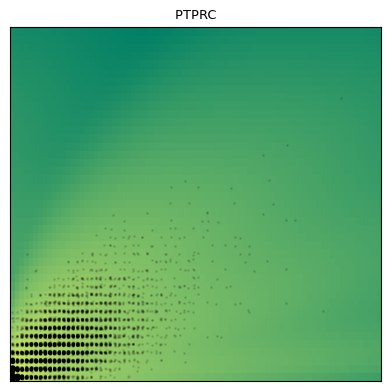

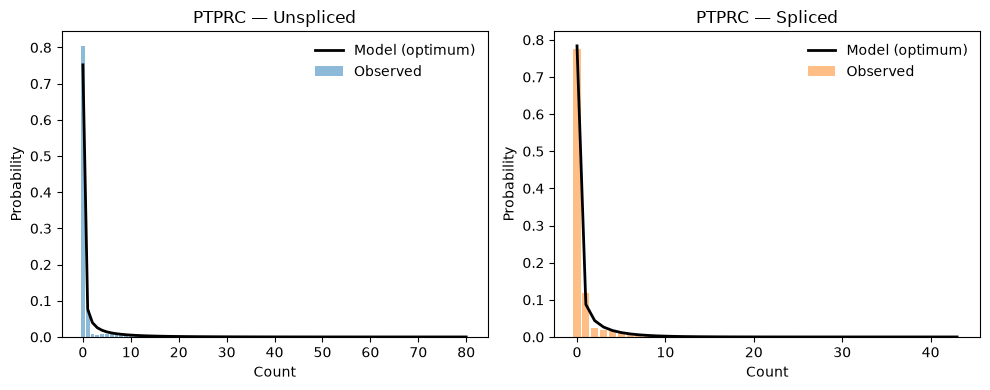

In [17]:
search_result.plot_gene_distributions(search_data, sz=(1, 1), figsize=(4, 4),
                                      marg='joint', savefig=False)

C = plt.rcParams['axes.prop_cycle'].by_key()['color']

# ── Marginal comparison ──────────────────────────────────────────────────────
gene_idx = 0
lm = search_data.M[:, gene_idx]
pss_opt = bursty.eval_model_pss(
    search_result.phys_optimum[gene_idx], lm,
    samp=search_result.samp_optimum,
)
pss_u = pss_opt.sum(axis=1)   # unspliced marginal
pss_s = pss_opt.sum(axis=0)   # spliced marginal

obs_u = np.bincount(
    search_data.layers[0, :, gene_idx].astype(int),
    minlength=lm[0],
).astype(float)
obs_u /= obs_u.sum()

obs_s = np.bincount(
    search_data.layers[1, :, gene_idx].astype(int),
    minlength=lm[1],
).astype(float)
obs_s /= obs_s.sum()

fig, (ax_u, ax_s) = plt.subplots(1, 2, figsize=(10, 4))
for ax, obs, pss_m, label, color in [
    (ax_u, obs_u, pss_u, 'Unspliced', C[0]),
    (ax_s, obs_s, pss_s, 'Spliced',   C[1]),
]:
    ax.bar(np.arange(len(obs)), obs, color=color, alpha=0.5, label='Observed')
    ax.plot(np.arange(len(pss_m)), pss_m, 'k-', lw=2, label='Model (optimum)')
    ax.set_xlabel('Count'); ax.set_ylabel('Probability')
    ax.set_title(f'{search_data.gene_names[gene_idx]} — {label}')
    ax.legend(frameon=False)
plt.tight_layout()
plt.savefig('figures/models_inference_fit.png', dpi=150, bbox_inches='tight')
plt.show()

### 10.6 · KLD landscape

With multiple sampling-parameter grid points the KLD landscape shows which
technical-noise level best explains the data.  With `seq_model='None'` there
is a single point; this cell generalises to multi-point grids.

In [18]:
print("KLD per grid point per gene:")
print(search_result.klds)
print(f"\nTotal KLD at each grid point: {search_result.obj_func}")
print(f"Selected grid point index:    {search_result.samp_optimum_ind}")

param_lin = 10 ** search_result.phys_optimum[0]
b_opt, beta_opt, gamma_opt = param_lin
print(f"\nFinal fitted parameters for {search_data.gene_names[0]}:")
print(f"  Burst size  b     = {b_opt:.3f}")
print(f"  mRNA decay  β     = {beta_opt:.4f}  (half-life ≈ {np.log(2)/beta_opt:.1f} a.u.)")
print(f"  Splicing    γ     = {gamma_opt:.4f}  (half-life ≈ {np.log(2)/gamma_opt:.1f} a.u.)")

KLD per grid point per gene:
[[0.12105088]]

Total KLD at each grid point: [0.12105088]
Selected grid point index:    0

Final fitted parameters for PTPRC:
  Burst size  b     = 12.359
  mRNA decay  β     = 9.0941  (half-life ≈ 0.1 a.u.)
  Splicing    γ     = 19.5185  (half-life ≈ 0.0 a.u.)


---
## Where next

- Gene-length correction for the Poisson sequencing model (`use_lengths`):
  `sequencing_noise.ipynb` §2 fits it with the poly(A) length reference, and
  `rust_pipeline.ipynb` Part 2 runs it on the all-Rust path.
- A fit done by hand, from `get_MoM` through `scipy.optimize.minimize`:
  `reaction_networks.ipynb` §7 (two species) and `protein_bursty.ipynb` (three species).
- Comparing two models on the same gene: `model_comparison.ipynb`.
